# MSIN0143 Programming for Business Analytics

## **RQ:** Which factors (road, time, weather and lighting conditions) are most associated with/affect the severity of a collision?

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

FOLDER = '/content/drive/MyDrive/Masters/MSIN0143 Programming for Business Analytics Group Coursework/data/'
DATA_PATH = FOLDER + 'dft-road-casualty-statistics-collision-2025.csv'
DICT_PATH = FOLDER + 'dft-road-casualty-statistics-road-safety-open-dataset-data-guide-2025.xlsx'

Mounted at /content/drive


In [ ]:
raw = pd.read_csv(DATA_PATH, low_memory=False)
df = raw.copy()

dictionary = pd.read_excel(DICT_PATH, sheet_name='2024_code_list')
dictionary = dictionary[dictionary['table'] == 'collision']

In [ ]:
df.dtypes

,0
collision_index,object
collision_year,int64
collision_ref_no,object
location_easting_osgr,float64
location_northing_osgr,float64
longitude,float64
latitude,float64
police_force,int64
collision_severity,int64
number_of_vehicles,int64


# Data Cleaning

The dataset contains 101,525 collisions recorded by police in Great Britain in 2025, with 44 attributes. This analysis keeps 21 columns relevant to the research question: collision severity, and road, time, weather and lighting conditions. All other columns are dropped. STATS19 records every attribute as a numeric code, so the data guide (Department for Transport, 2025) is used throughout cleaning to interpret values.

In [ ]:
# Selecting columns
analysis_cols = [
    'collision_ref_no', 'collision_severity', 'number_of_vehicles', 'number_of_casualties',
    'date', 'day_of_week', 'time', 'local_authority_ons_district', 'first_road_class', 'road_type',
    'speed_limit', 'junction_detail', 'junction_control', 'second_road_class', 'pedestrian_crossing',
    'light_conditions', 'weather_conditions', 'road_surface_conditions',
    'special_conditions_at_site', 'carriageway_hazards', 'urban_or_rural_area'
]

# Keep columns only used for this analysis
df = df[analysis_cols].copy()
print(f"Original: {raw.shape}, Analysis: {df.shape}")

df.head()

Original: (101525, 44), Analysis: (101525, 21)


,collision_ref_no,collision_severity,number_of_vehicles,number_of_casualties,date,day_of_week,time,local_authority_ons_district,first_road_class,road_type,...,junction_detail,junction_control,second_road_class,pedestrian_crossing,light_conditions,weather_conditions,road_surface_conditions,special_conditions_at_site,carriageway_hazards,urban_or_rural_area
0,17M101925,3,1,1,04/02/2025,3,15:00,E06000002,4,6,...,0,-1,0,13,1,1,1,-1,0,1
1,17L205225,3,2,1,07/05/2025,4,09:35,E06000003,5,6,...,0,-1,0,0,1,1,1,-1,0,1
2,070971700,3,2,2,27/11/2025,5,18:18,E06000006,6,6,...,13,2,6,15,4,1,2,-1,0,2
3,070403274,3,2,1,15/05/2025,5,16:30,E06000007,5,6,...,0,-1,0,0,1,1,1,-1,0,2
4,071000604,3,7,1,08/12/2025,2,07:45,E06000007,1,3,...,0,-1,0,-1,4,1,2,-1,0,2


In [ ]:
# Check for duplicate rows and collision references
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df['collision_ref_no'].duplicated().sum())

Duplicate rows: 0
Duplicate IDs: 0


In [ ]:
# Replacing "unknown" values with missing values NaN
unknown_value = {
    'road_type': [9],
    'speed_limit': [99],
    'junction_detail': [99],
    'junction_control': [9],
    'second_road_class': [9],
    'pedestrian_crossing': [99],
    'weather_conditions': [9],
    'road_surface_conditions': [9],
    'special_conditions_at_site': [9],
    'carriageway_hazards': [99],
    'urban_or_rural_area': [3]
}

df = df.replace(-1, np.nan)
df = df.replace(unknown_value, np.nan)

# % missing per column after recoding
df.isna().mean().mul(100).round(1).sort_values()

,0
collision_ref_no,0.0
collision_severity,0.0
number_of_vehicles,0.0
number_of_casualties,0.0
date,0.0
day_of_week,0.0
time,0.0
local_authority_ons_district,0.0
first_road_class,0.0
speed_limit,0.0


In [ ]:
# Fix structural missing values

# Junction control does not apply when there is no junction, so recode as 'not at junction'
df.loc[(df['junction_detail'] == 0) & df['junction_control'].isna(), 'junction_control'] = 0

# Drop a mostly empty column that has been replaced by carriageway_hazards
df = df.drop(columns=['special_conditions_at_site'], errors='ignore')

In [ ]:
# Missing value report
# Compare the severity of rows with missing values against all collisions

fatal = df['collision_severity'] == 1     # 1 = Fatal
serious = df['collision_severity'] == 2   # 2 = Serious

missing = df.isna()

print(f"Overall: {fatal.mean():.1%} fatal, {serious.mean():.1%} serious")

report = pd.DataFrame({
    'missing_%': missing.mean() * 100,
    'fatal_%_if_missing': [fatal[missing[c]].mean() * 100 for c in df.columns],
    'serious_%_if_missing': [serious[missing[c]].mean() * 100 for c in df.columns],
}).round(2)
report[missing.any()].sort_values('missing_%', ascending=False)

Overall: 1.4% fatal, 24.8% serious


,missing_%,fatal_%_if_missing,serious_%_if_missing
junction_detail,8.01,0.54,17.08
pedestrian_crossing,6.73,0.03,10.69
carriageway_hazards,5.95,0.02,10.86
junction_control,4.47,0.31,10.84
weather_conditions,2.35,0.13,12.33
road_surface_conditions,1.95,0.10,9.41
road_type,1.92,0.00,10.70
second_road_class,0.22,2.28,11.87
light_conditions,0.02,0.00,25.00
first_road_class,0.01,0.00,0.00


In [ ]:
# Handle remaining missing values
# Drop rows where few values are missing; label the rest 'Unknown' (next cell)

drop_rows = ['first_road_class', 'road_type', 'second_road_class', 'light_conditions',
               'weather_conditions', 'road_surface_conditions', 'urban_or_rural_area']
unknown_cat = ['junction_detail', 'junction_control', 'pedestrian_crossing', 'carriageway_hazards']

before = len(df)
df = df.dropna(subset=drop_rows)
print(f"Removed {before - len(df):,} rows ({(before - len(df)) / before:.1%}), {len(df):,} remain")

Removed 4,573 rows (4.5%), 96,952 remain


In [ ]:
# Replace codes with labels from the DfT data guide
# Derive nation from the district code before the codes are replaced
df['nation'] = df['local_authority_ons_district'].str[0].map(
    {'E': 'England', 'W': 'Wales', 'S': 'Scotland'})

coded_cols = ['collision_severity', 'day_of_week', 'local_authority_ons_district', 'first_road_class',
              'road_type', 'junction_detail', 'junction_control', 'second_road_class',
              'pedestrian_crossing', 'light_conditions', 'weather_conditions',
              'road_surface_conditions', 'carriageway_hazards', 'urban_or_rural_area']

for col in coded_cols:
    rows = dictionary[dictionary['field name'] == col]
    keys = rows['code/format'] if col == 'local_authority_ons_district' else pd.to_numeric(rows['code/format'], errors='coerce')
    mapping = dict(zip(keys, rows['label'].fillna('None present')))   # fill blank labels
    if col == 'local_authority_ons_district':
        # Add codes missing from the guide
        mapping.update({'E08000038': 'Barnsley', 'E08000039': 'Sheffield'})
    df[col] = df[col].map(mapping)

df[unknown_cat] = df[unknown_cat].fillna('Unknown')
df['speed_limit'] = df['speed_limit'].astype(int)   # keep as a number
df.head()

,collision_ref_no,collision_severity,number_of_vehicles,number_of_casualties,date,day_of_week,time,local_authority_ons_district,first_road_class,road_type,...,junction_detail,junction_control,second_road_class,pedestrian_crossing,light_conditions,weather_conditions,road_surface_conditions,carriageway_hazards,urban_or_rural_area,nation
0,17M101925,Slight,1,1,04/02/2025,Tuesday,15:00,Middlesbrough,B,Single carriageway,...,Not at junction or within 20 metres,Not at junction or within 20 metres,Not at junction or within 20 metres,Zebra crossing,Daylight,Fine no high winds,Dry,None present,Urban,England
1,17L205225,Slight,2,1,07/05/2025,Wednesday,09:35,Redcar and Cleveland,C,Single carriageway,...,Not at junction or within 20 metres,Not at junction or within 20 metres,Not at junction or within 20 metres,No physical crossing facility within 50m,Daylight,Fine no high winds,Dry,None present,Urban,England
2,070971700,Slight,2,2,27/11/2025,Thursday,18:18,Halton,Unclassified,Single carriageway,...,T or staggered junction,Auto traffic signal,Unclassified,Pedestrian phase at traffic signal,Darkness - lights lit,Fine no high winds,Wet or damp,None present,Rural,England
3,070403274,Slight,2,1,15/05/2025,Thursday,16:30,Warrington,C,Single carriageway,...,Not at junction or within 20 metres,Not at junction or within 20 metres,Not at junction or within 20 metres,No physical crossing facility within 50m,Daylight,Fine no high winds,Dry,None present,Rural,England
4,071000604,Slight,7,1,08/12/2025,Monday,07:45,Warrington,Motorway,Dual carriageway,...,Not at junction or within 20 metres,Not at junction or within 20 metres,Not at junction or within 20 metres,Unknown,Darkness - lights lit,Fine no high winds,Wet or damp,None present,Rural,England


In [ ]:
# Outlier check and final checks
# Check count variables for extreme values
print(df[['number_of_vehicles', 'number_of_casualties']].describe().round(2))

# Set severity as an ordered category
df['collision_severity'] = pd.Categorical(df['collision_severity'],
                                          categories=['Slight', 'Serious', 'Fatal'], ordered=True)
print(df['collision_severity'].value_counts(normalize=True).mul(100).round(1))

assert df.isna().sum().sum() == 0, "Missing values remain"
print(df.shape)

       number_of_vehicles  number_of_casualties
count            96952.00              96952.00
mean                 1.82                  1.27
std                  0.70                  0.83
min                  1.00                  1.00
25%                  1.00                  1.00
50%                  2.00                  1.00
75%                  2.00                  1.00
max                 17.00                142.00
collision_severity
Slight     73.1
Serious    25.4
Fatal       1.5
Name: proportion, dtype: float64
(96952, 21)


**1. Small counts in the missing value report.** Some columns have only a handful of missing rows: light conditions (16), first road class (6) and urban/rural area (4). Their fatal and serious percentages are therefore unreliable (e.g. "50% serious" is based on 4 collisions) and are not interpreted.

**2. Inconsistent junction fields.** second_road_class records the class of the second road at a junction. However, around 19,800 collisions recorded a second road class despite junction_detail stating "not at junction". Since junction_detail is the primary junction field in the 2024 STATS19 specification, it is treated as the more reliable of the two.

# Exploratory Data Analysis

## Target variable: Collission Severity

In [ ]:
severity = df['collision_severity']

severity_summary = pd.DataFrame({
    'count': severity.value_counts().sort_index(),
    'percent': severity.value_counts(normalize=True).mul(100).round(1)
}).reindex(['Fatal', 'Serious', 'Slight'])

raw_severity = raw['collision_severity'].map({1: 'Fatal', 2: 'Serious', 3: 'Slight'})
severity_summary['percent_before_cleaning'] = (
    raw_severity.value_counts(normalize=True).mul(100).round(1).reindex(['Fatal', 'Serious', 'Slight']))

severity_summary



,count,percent,percent_before_cleaning
collision_severity,,,
Fatal,1444,1.5,1.4
Serious,24624,25.4,24.8
Slight,70884,73.1,73.8


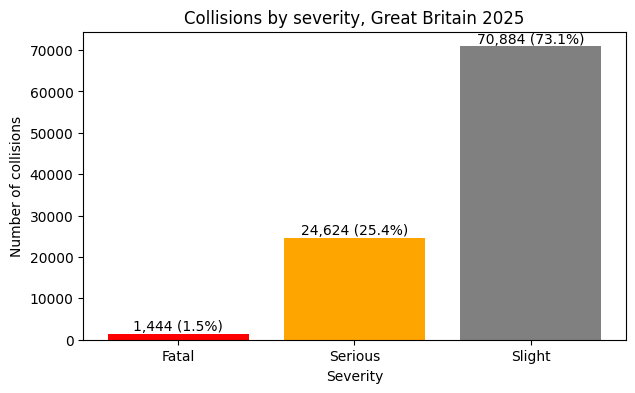

In [ ]:
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(severity_summary.index, severity_summary['count'],
       color=["red", "orange", "gray"])
for i in range(len(severity_summary)):
  count = severity_summary['count'].iloc[i]
  pct = severity_summary['percent'].iloc[i]
  ax.text(i, count, f"{count:,} ({pct}%)", ha='center', va='bottom')

ax.set_title('Collisions by severity, Great Britain 2025')
ax.set_xlabel('Severity')
ax.set_ylabel('Number of collisions')
plt.show()


## Missing values before and after cleaning

In [ ]:
before = raw[analysis_cols].replace(-1, np.nan).replace(unknown_value, np.nan)

treatment = {c: 'Rows dropped' for c in drop_rows}
treatment.update({c: "Labelled 'Unknown'" for c in unknown_cat})
treatment['junction_control'] = "Set to 'not at junction' if junction_detail = 0;
rest 'Unknown'"
treatment['special_conditions_at_site'] = 'Column dropped'

mv = pd.DataFrame({'missing_before_%': before.isna().mean() * 100})
mv['unknown_after_%'] = pd.Series({c: (df[c] == 'Unknown').mean() * 100 for c in unknown_cat})
mv['treatment'] =pd.Series(treatment)

mv = mv[mv['missing_before_%'] > 0].sort_value('missing_before_%', ascending=False).round(2)
mv['unknown_after_%'] = mv['unknown_after_%'].fillna(0)

print(f"Rows: {len(raw):,} before → {len(df):,} after "
      f"({len(raw) - len(df):,} dropped, {(len(raw) - len(df)) / len(raw):.1%})")
print("Missing values left after cleaning:", df.isna().sum().sum())
mv


SyntaxError: unterminated string literal (detected at line 5) (4201696658.py, line 5)

In [ ]:
ax = mv[['missing_before_%', 'unknown_after_%']].plot(
    kind='barh', figsize=(8,5), color=['gray', 'blue'])
ax.invert_yaxis()
ax.set_xlabel('% of collisions')
ax.set_ylabel('')
ax.set_title('Missing values before cleaning vs "Unknown" remaining after')
ax.legend(['Missing before cleaning', "Labelled 'Unknown' after cleaning"],
          frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()


NameError: name 'mv' is not defined

## Distribution of Explanatory Variables

### Numeric Variables

### Categorical Variables

### Monthly trend in Collisions

### Collisions by location (Top 10 local authorities)

## Explanatory variables and Collision Severity

In [98]:
# def severity_by(x, category_order=None, title=None):
#   """Stacked bar chart of severity (%) for each category of x, labelled with the number of collisions."""
#   table = pd.crosstab(df[x], df['collision_severity'])
#   if category_order:
#       table = table.reindex(category_order)
#   pct = table.div(table.sum(axis = 1), axis = 0) * 100  # % of severity within each condition

#   # Stacked bars of counts: slight -> fatal
#   ax = pct.plot(kind = 'bar', stacked = True, figsize = (10, 6), width = 0.7,
#                 color=['#cce3fd', '#519ced', '#0e3d7e'])

#   # Label
#   for i, cat in enumerate(pct.index):
#       ax.text(i, pct.loc[cat, 'Slight'] + pct.loc[cat, 'Serious'] / 2, f"{pct.loc[cat, 'Serious']:.1f}%",
#               ha='center', va='center', color='white', fontsize=8)
#       ax.text(i, 101, f"{pct.loc[cat, 'Fatal']:.1f}% fatal\nn = {table.loc[cat].sum():,}",
#               ha='center', va='bottom', fontsize=8)

#   ax.set_ylim(0, 115)
#   ax.set_ylabel('% of collisions')
#   ax.set_xlabel('')
#   ax.set_title(title or f'Collision severity by {x}')
#   ax.legend(title='Severity', bbox_to_anchor=(1.01, 1), loc='upper left')
#   plt.xticks(rotation=45, ha='right')
#   plt.tight_layout()
#   plt.show()

#   # Summary table: % per severity level plus the number of collisions
#   pct['collisions'] = table.sum(axis=1)
#   return pct.round(2)

def severity_by(x, category_order=None, title=None):
  """Stacked bar chart of severity number of collisions for each category of x, split by severity."""
  table = pd.crosstab(df[x], df['collision_severity'])
  if category_order:
    table = table.reindex(category_order)
  pct = table.div(table.sum(axis=1), axis=0) * 100  # % of severity within each condition

  # Stacked bars of counts: slight -> fatal
  ax = table.plot(kind='bar', stacked=True, figsize=(10, 6), width=0.7, color=['#cce3fd', '#519ced', '#0e3d7e'])

  # Label
  for i, cat in enumerate(pct.index):
    total = table.loc[cat].sum()
    ax.text(i, total, f"n = {total:,}\n{pct.loc[cat, 'Slight']:.1f}% slight\n"
            f"{pct.loc[cat, 'Serious']:.1f}% serious\n{pct.loc[cat, 'Fatal']:.1f}% fatal",
            ha='center', va='bottom', fontsize=8)

  ax.set_ylim(0, table.sum(axis=1).max() * 1.3)
  ax.set_ylabel('Number of collisions')
  ax.set_xlabel('')
  ax.set_title(title or f'Collision severity by {x}')
  ax.legend(title='Severity', bbox_to_anchor=(1.01, 1), loc='upper left')
  plt.xticks(rotation=45, ha='right')
  plt.tight_layout()
  plt.show()

  # # Summary table: severity level plus the number of collisions
  # pct['collisions'] = table.sum(axis=1)
  # return pct.round(2)

  # Summary table: number of collisions for each severity level, plus the total
  table['collisions'] = table.sum(axis=1)
  return table

### Road Factors
* Speed limit
* Road type
* Road class
* Junction detail
* Junction control

### Environmental Factors
* Light conditions
* Weather conditions
* Road surface conditions

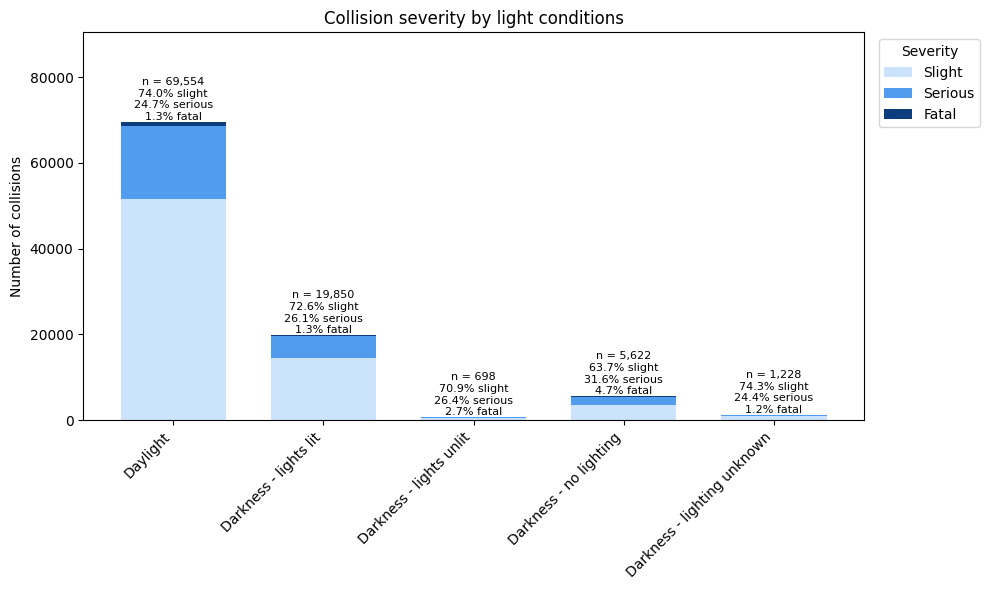

collision_severity,Slight,Serious,Fatal,collisions
light_conditions,,,,
Daylight,51494,17180,880,69554
Darkness - lights lit,14403,5181,266,19850
Darkness - lights unlit,495,184,19,698
Darkness - no lighting,3579,1779,264,5622
Darkness - lighting unknown,913,300,15,1228


In [99]:
# Light conditions
severity_by('light_conditions', category_order = ['Daylight', 'Darkness - lights lit', 'Darkness - lights unlit', 'Darkness - no lighting', 'Darkness - lighting unknown'], title = 'Collision severity by light conditions')

Most collisions occur during daylight (69,554), followed by darkness with street lights lit (19,850). Severity level increases sharply when there is no street lighting, with 4.7% fatal and 31.6% serious collisions, compared to 1.3% fatal and 24.7% serious collisions in daylight. Darkness with lights unlit has the second most significant collision severity, with a fatal rate of 2.7%.

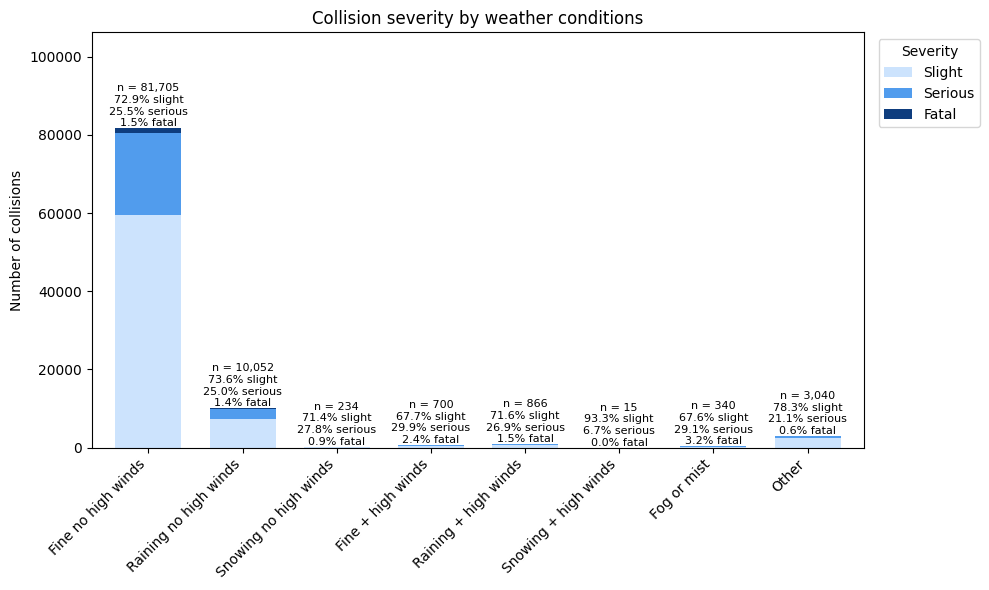

collision_severity,Slight,Serious,Fatal,collisions
weather_conditions,,,,
Fine no high winds,59597,20864,1244,81705
Raining no high winds,7402,2512,138,10052
Snowing no high winds,167,65,2,234
Fine + high winds,474,209,17,700
Raining + high winds,620,233,13,866
Snowing + high winds,14,1,0,15
Fog or mist,230,99,11,340
Other,2380,641,19,3040


In [100]:
# Weather conditions
severity_by('weather_conditions', category_order = ['Fine no high winds', 'Raining no high winds', 'Snowing no high winds', 'Fine + high winds', 'Raining + high winds', 'Snowing + high winds', 'Fog or mist', 'Other'], title = 'Collision severity by weather conditions')

Most collisions happen in fine weather without any high winds. Rain makes little difference to collision severity.

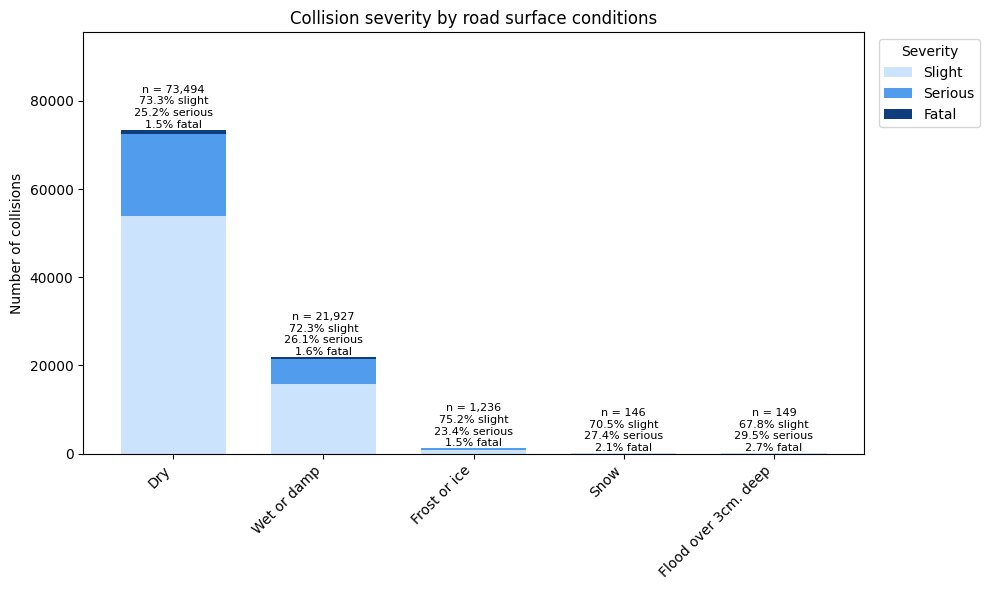

collision_severity,Slight,Serious,Fatal,collisions
road_surface_conditions,,,,
Dry,53896,18525,1073,73494
Wet or damp,15855,5726,346,21927
Frost or ice,929,289,18,1236
Snow,103,40,3,146
Flood over 3cm. deep,101,44,4,149


In [101]:
# Road surface conditions
severity_by('road_surface_conditions', category_order = ['Dry', 'Wet or damp', 'Frost or ice', 'Snow', 'Flood over 3cm. deep'], title = 'Collision severity by road surface conditions')

### Time Factors
* Hour of day
* Day of week
* Month

In [102]:
def severity_over_time(x, category_order=None, title=None):
  """Collisions and % slight, serious and fatal across hour of day and month"""
  table = pd.crosstab(df[x], df['collision_severity'])
  if category_order:
    table = table.reindex(category_order)
  pct = table.div(table.sum(axis=1), axis=0) * 100
  labels = table.index.astype(str)

  fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)
  axes[0].bar(labels, table.sum(axis=1), color='#519ced')
  axes[0].set_ylabel('Number of collisions')
  for ax, level, colour in zip(axes[1:], ['Slight', 'Serious', 'Fatal'], ['#84b9f3', '#519ced', '#0e3d7e']):
    ax.plot(labels, pct[level], marker='o', color=colour)
    ax.axhline((df['collision_severity'] == level).mean() * 100, color='grey', linestyle='--')
    ax.set_ylabel(f'% {level.lower()}')
  axes[3].set_xlabel(x.replace('_', ' ').capitalize())
  fig.suptitle(title or f'Collisions and severity by {x}')
  plt.tight_layout()
  plt.show()

  pct['collisions'] = table.sum(axis=1)
  return pct.round(2)

In [103]:
df['hour'] = df['time'].str[:2].astype(int)
df['month'] = df['date'].str[3:5].astype(int)

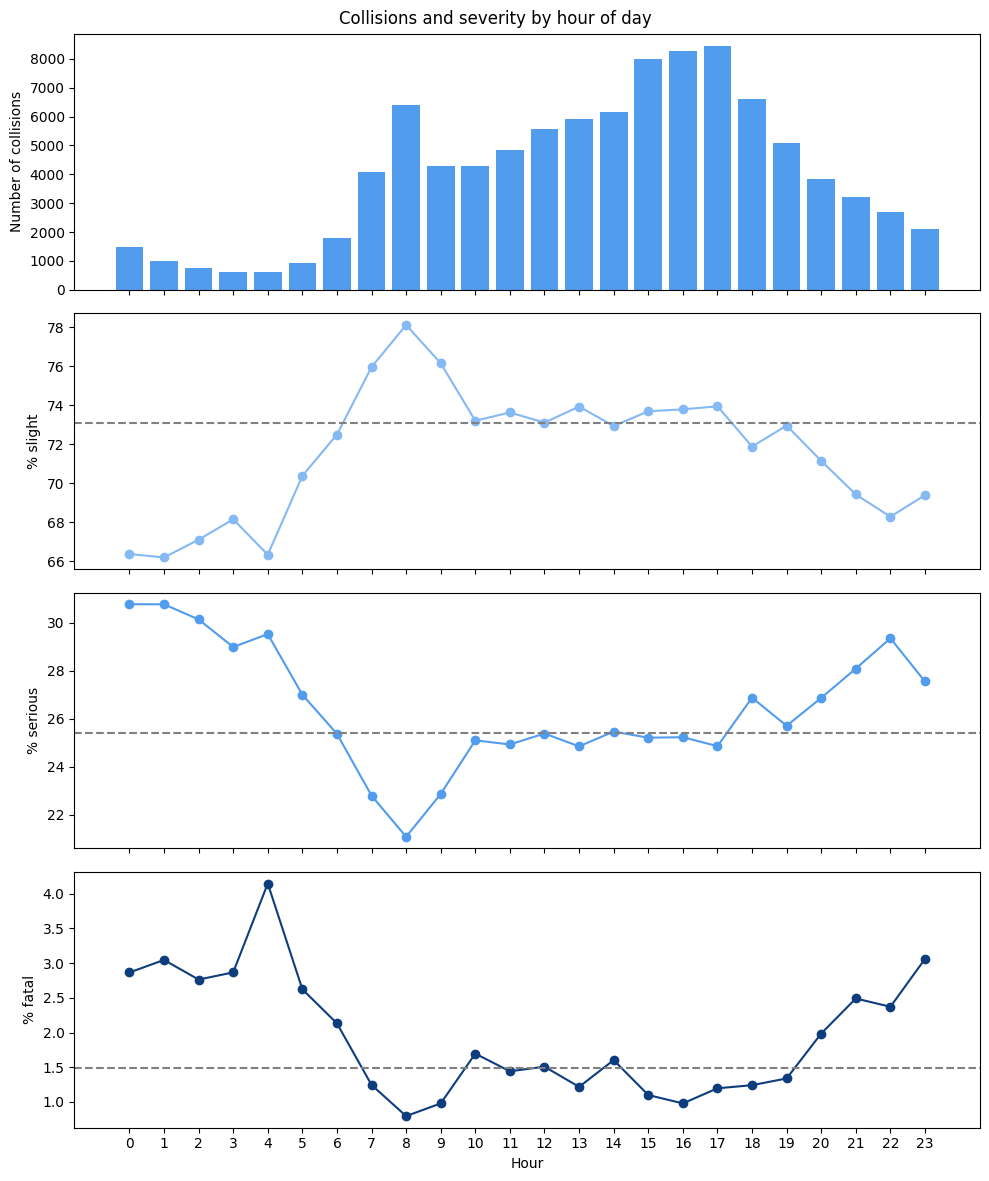

collision_severity,Slight,Serious,Fatal,collisions
hour,,,,
0,66.37,30.76,2.86,1466
1,66.19,30.76,3.05,985
2,67.11,30.13,2.76,760
3,68.15,28.98,2.87,628
4,66.33,29.52,4.15,603
5,70.38,26.99,2.62,915
6,72.50,25.36,2.13,1782
7,75.96,22.79,1.25,4094
8,78.13,21.07,0.80,6401


In [104]:
# Hour of day
severity_over_time('hour', title = 'Collisions and severity by hour of day')

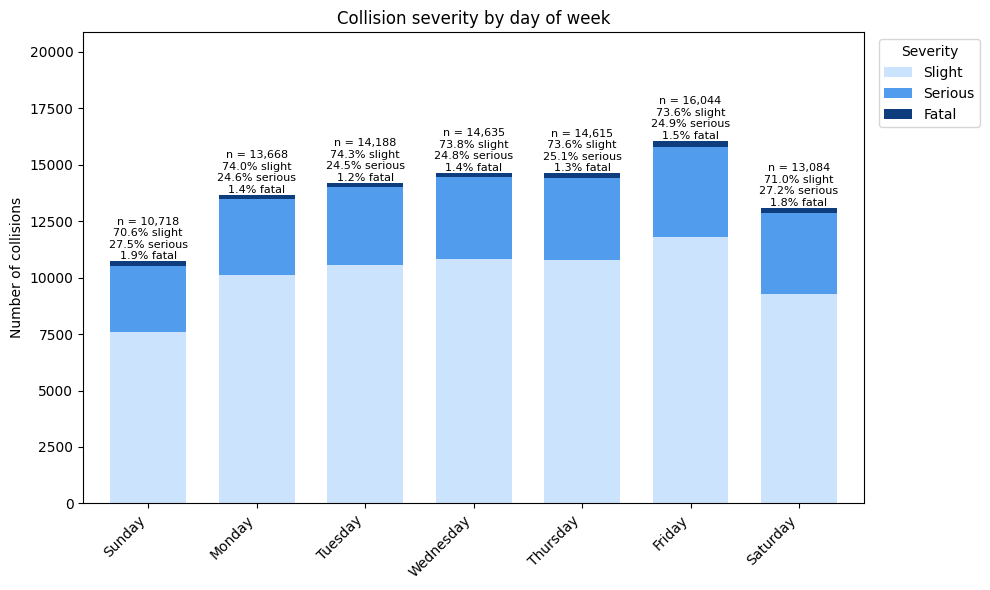

collision_severity,Slight,Serious,Fatal,collisions
day_of_week,,,,
Sunday,7571,2945,202,10718
Monday,10118,3364,186,13668
Tuesday,10539,3474,175,14188
Wednesday,10801,3633,201,14635
Thursday,10758,3663,194,14615
Friday,11810,3988,246,16044
Saturday,9287,3557,240,13084


In [105]:
# Day of week
severity_by('day_of_week', category_order = ['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday'], title = 'Collision severity by day of week')

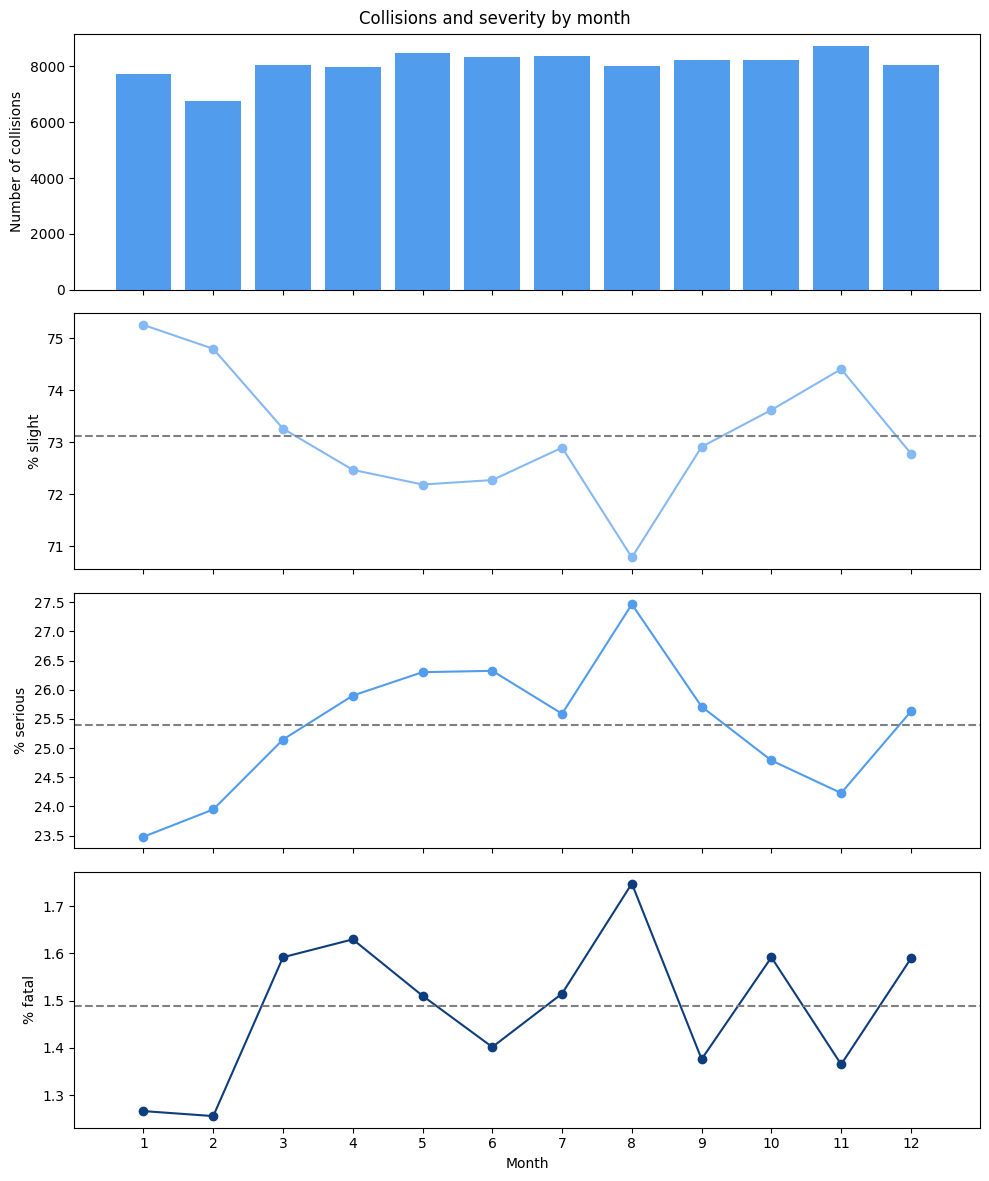

collision_severity,Slight,Serious,Fatal,collisions
month,,,,
1,75.26,23.48,1.27,7739
2,74.80,23.95,1.26,6769
3,73.26,25.15,1.59,8041
4,72.47,25.90,1.63,7977
5,72.19,26.30,1.51,8475
6,72.27,26.32,1.40,8346
7,72.90,25.59,1.51,8383
8,70.79,27.47,1.75,8010
9,72.91,25.71,1.38,8211


In [106]:
# Month
severity_over_time('month', title = 'Collisions and severity by month')

### Urban vs Rural area

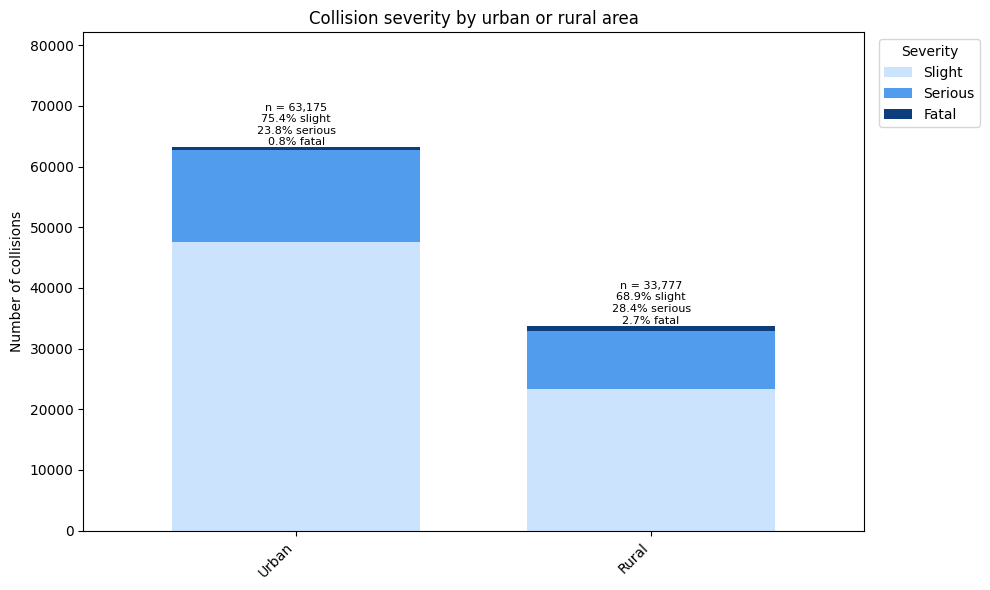

collision_severity,Slight,Serious,Fatal,collisions
urban_or_rural_area,,,,
Urban,47616,15042,517,63175
Rural,23268,9582,927,33777


In [107]:
# Urban vs rural area
severity_by('urban_or_rural_area', category_order = ['Urban', 'Rural'], title = 'Collision severity by urban or rural area')

### Carriageway Hazards

In [108]:
# Categorise carriageway hazards into: Hazards present, no hazards, and Unknown
hazard_types = ['Defective traffic signals',                                                 # code 11
                'Permanent road signing or markings defective or obscured or inadequate',    # 12
                'Roadworks',                                                                 # 13
                'Oil or diesel',                                                             # 14
                'Mud',                                                                       # 15
                'Dislodged vehicle load in carriageway',                                     # 16
                'Other object in carriageway',                                               # 17
                'Involvement with previous collision',                                       # 18
                'Pedestrian in carriageway - not injured',                                   # 19
                'Any animal in carriageway (except ridden horse)',                           # 20
                'Poor or defective road surface']                                            # 21

df['hazard_present'] = 'Unknown'
df.loc[df['carriageway_hazards'] == 'None present', 'hazard_present'] = 'No hazard'
df.loc[df['carriageway_hazards'].isin(hazard_types), 'hazard_present'] = 'Hazard present'

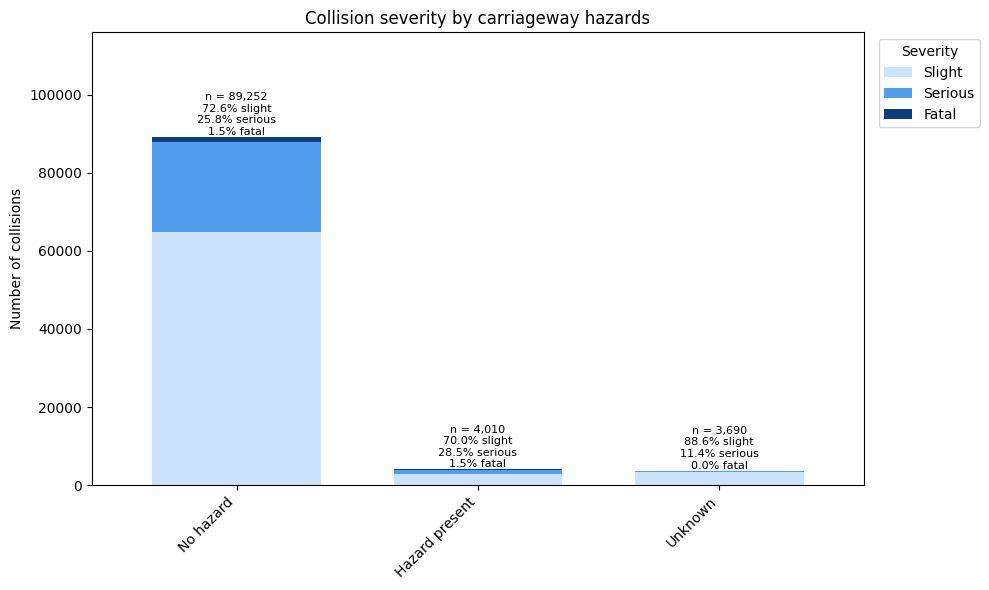

collision_severity,Slight,Serious,Fatal,collisions
hazard_present,,,,
No hazard,64806,23063,1383,89252
Hazard present,2808,1141,61,4010
Unknown,3270,420,0,3690


In [109]:
severity_by('hazard_present', category_order = ['No hazard', 'Hazard present', 'Unknown'], title = 'Collision severity by carriageway hazards')

In [111]:
# # % of severity for each hazard type + number of collisions
# hazards = pd.crosstab(df['carriageway_hazards'], df['collision_severity'], normalize='index').mul(100).round(1)
# hazards['collisions'] = df['carriageway_hazards'].value_counts()
# hazards.sort_values('collisions', ascending=False)

# Number of collisions for each hazard type and severity level
hazards = pd.crosstab(df['carriageway_hazards'], df['collision_severity'])
hazards['collisions'] = hazards.sum(axis=1)
hazards.sort_values('collisions', ascending=False).reset_index()

collision_severity,carriageway_hazards,Slight,Serious,Fatal,collisions
0,None present,64806,23063,1383,89252
1,Unknown,3270,420,0,3690
2,Roadworks,765,241,9,1015
3,Other object in carriageway,570,265,26,861
4,Poor or defective road surface,330,162,7,499
5,Mud,215,97,1,313
6,Any animal in carriageway (except ridden horse),187,83,1,271
7,Defective traffic signals,196,56,3,255
8,Permanent road signing or markings defective o...,160,72,7,239
9,Involvement with previous collision,108,48,5,161


## Summary of EDA Findings